In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

ticker = "NVDA"

data = yf.download(
    ticker,
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

print(data.head())
print(data.tail())

c:\Users\joshwanth\AppData\Local\Programs\Python\Python313\Lib\site-packages\yfinance\scrapers\history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


Price       Adj Close     Close      High      Low      Open     Volume
Ticker           NVDA      NVDA      NVDA     NVDA      NVDA       NVDA
Date                                                                   
2021-01-04  13.046200  13.11350  13.65250  12.9625  13.10425  560640000
2021-01-05  13.335954  13.40475  13.44350  13.0870  13.09975  322760000
2021-01-06  12.549757  12.61450  13.24500  12.5860  13.22250  580424000
2021-01-07  13.275515  13.34400  13.37775  12.8865  12.96750  461480000
2021-01-08  13.208609  13.27675  13.42100  13.0420  13.36250  292528000
Price        Adj Close       Close        High         Low        Open  \
Ticker            NVDA        NVDA        NVDA        NVDA        NVDA   
Date                                                                     
2025-12-24  188.169678  188.610001  188.910004  186.589996  187.940002   
2025-12-26  190.085190  190.529999  192.690002  188.000000  189.919998   
2025-12-29  187.780594  188.220001  188.759995  185.91

In [2]:
print("Number of observations:", len(data))

print("\nMissing values:")
print(data.isna().sum())

print("\nDate range:")
print(data.index.min(), "to", data.index.max())

Number of observations: 1255

Missing values:
Price      Ticker
Adj Close  NVDA      0
Close      NVDA      0
High       NVDA      0
Low        NVDA      0
Open       NVDA      0
Volume     NVDA      0
dtype: int64

Date range:
2021-01-04 00:00:00 to 2025-12-31 00:00:00


In [3]:
print("Duplicate dates:", data.index.duplicated().sum())

Duplicate dates: 0


In [4]:
date_diffs = data.index.to_series().diff()

print("\nLargest gaps:")
print(date_diffs.sort_values(ascending=False).head(10))


Largest gaps:
Date
2024-01-02   4 days
2025-04-21   4 days
2023-01-03   4 days
2024-05-28   4 days
2023-12-26   4 days
2023-01-17   4 days
2022-04-18   4 days
2021-09-07   4 days
2024-09-03   4 days
2025-09-02   4 days
Name: Date, dtype: timedelta64[s]


In [5]:
prices = data["Adj Close"].squeeze()

returns = prices.pct_change()

df = pd.DataFrame({
    "price": prices,
    "return": returns
})
df = df.dropna()
print(df.head())


                price    return
Date                           
2021-01-05  13.335954  0.022210
2021-01-06  12.549757 -0.058953
2021-01-07  13.275515  0.057830
2021-01-08  13.208609 -0.005040
2021-01-11  13.551589  0.025966


In [6]:
n_lags = 5

for lag in range(1, n_lags + 1):
    df[f"lag_{lag}"] = df["return"].shift(lag)

df["target"] = df["return"].shift(-1)

df = df.dropna()
print(df['target'].head())




Date
2021-01-12    0.003486
2021-01-13   -0.024498
2021-01-14   -0.025814
2021-01-15    0.012889
2021-01-19    0.026142
Name: target, dtype: float64


In [7]:
features = [f"lag_{i}" for i in range(1, n_lags + 1)]

X = df[features]
y = df["target"]

In [8]:
test_start = "2025-01-01"

development = df[df.index < test_start].copy()
test = df[df.index >= test_start].copy()

print("Development:", development.index.min(), development.index.max())
print("Test:", test.index.min(), test.index.max())

Development: 2021-01-12 00:00:00 2024-12-31 00:00:00
Test: 2025-01-02 00:00:00 2025-12-30 00:00:00


In [9]:
validation_periods = [
    ("2023-01-01", "2023-04-01"),
    ("2023-04-01", "2023-07-01"),
    ("2023-07-01", "2023-10-01"),
    ("2023-10-01", "2024-01-01"),
    ("2024-01-01", "2024-04-01"),
    ("2024-04-01", "2024-07-01"),
    ("2024-07-01", "2024-10-01"),
    ("2024-10-01", "2025-01-01")
]

In [10]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

alphas = [1e-6, 1e-5, 1e-4, 1e-3,
          1e-2, 1e-1, 1, 10, 100]

validation_results = []

for alpha in alphas:

    fold_results = []

    for val_start, val_end in validation_periods:

        train = development[
            development.index < val_start
        ]

        val = development[
            (development.index >= val_start) &
            (development.index < val_end)
        ]

        X_train = train[features]
        y_train = train["target"]

        X_val = val[features]
        y_val = val["target"]

        # Fit preprocessing ONLY on training data
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)

        # Ridge
        model = Ridge(alpha=alpha)

        model.fit(X_train_scaled, y_train)

        predictions = model.predict(X_val_scaled)
        
        mae = mean_absolute_error(y_val, predictions)
        rmse = np.sqrt(mean_squared_error(y_val, predictions))

        fold_results.append({
            "MAE": mae,
            "RMSE": rmse
        })

    validation_results.append({
        "alpha": alpha,
        "mean_MAE": np.mean([x["MAE"] for x in fold_results]),
        "mean_RMSE": np.mean([x["RMSE"] for x in fold_results])
    })

validation_results = pd.DataFrame(validation_results)

print(validation_results)

        alpha  mean_MAE  mean_RMSE
0    0.000001  0.023038   0.031240
1    0.000010  0.023038   0.031240
2    0.000100  0.023038   0.031240
3    0.001000  0.023038   0.031240
4    0.010000  0.023038   0.031240
5    0.100000  0.023038   0.031240
6    1.000000  0.023038   0.031240
7   10.000000  0.023036   0.031239
8  100.000000  0.023017   0.031229


In [ ]:
best_alpha = validation_results.loc[
    validation_results["mean_RMSE"].idxmin(),
    "alpha"
]

print("Best alpha:", best_alpha)

Best alpha: 100.0


In [12]:
X_dev = development[features]
y_dev = development["target"]

X_test = test[features]
y_test = test["target"]

scaler = StandardScaler()

X_dev_scaled = scaler.fit_transform(X_dev)
X_test_scaled = scaler.transform(X_test)

final_model = Ridge(alpha=best_alpha)

final_model.fit(X_dev_scaled, y_dev)

dev_predictions = final_model.predict(X_dev_scaled)
test_predictions = final_model.predict(X_test_scaled)


In [13]:
prediction_comparison = pd.DataFrame({
    "Actual Return": y_test.values,
    "Predicted Return": test_predictions
}, index=y_test.index)
print("\nPredicted Returns vs Actual Returns:")
print("=" * 65)

for date, row in prediction_comparison.iterrows():
    print(
        f"Date: {date.strftime('%Y-%m-%d')} | "
        f"Actual Return: {row['Actual Return']:.8f} | "
        f"Predicted Return: {row['Predicted Return']:.8f}"
    )


Predicted Returns vs Actual Returns:
Date: 2025-01-02 | Actual Return: 0.04453761 | Predicted Return: 0.00290265
Date: 2025-01-03 | Actual Return: 0.03433228 | Predicted Return: 0.00296780
Date: 2025-01-06 | Actual Return: -0.06216958 | Predicted Return: 0.00119270
Date: 2025-01-07 | Actual Return: -0.00021408 | Predicted Return: 0.00085436
Date: 2025-01-08 | Actual Return: -0.02997639 | Predicted Return: 0.00153897
Date: 2025-01-10 | Actual Return: -0.01971898 | Predicted Return: 0.00675302
Date: 2025-01-13 | Actual Return: -0.01103347 | Predicted Return: 0.00539356
Date: 2025-01-14 | Actual Return: 0.03400124 | Predicted Return: 0.00365069
Date: 2025-01-15 | Actual Return: -0.01959778 | Predicted Return: 0.00135901
Date: 2025-01-16 | Actual Return: 0.03099503 | Predicted Return: 0.00250068
Date: 2025-01-17 | Actual Return: 0.02265606 | Predicted Return: 0.00030276
Date: 2025-01-21 | Actual Return: 0.04430892 | Predicted Return: 0.00235328
Date: 2025-01-22 | Actual Return: 0.00101995

In [14]:
mean_return = y_dev.mean()

dev_baseline_predictions = np.full(
    len(y_dev),
    mean_return
)

test_baseline_predictions = np.full(
    len(y_test),
    mean_return
)

In [15]:
results = {
    "Ridge Training MAE":
        mean_absolute_error(y_dev, dev_predictions),

    "Ridge Training RMSE":
        np.sqrt(mean_squared_error(y_dev, dev_predictions)),

    "Ridge Test MAE":
        mean_absolute_error(y_test, test_predictions),

    "Ridge Test RMSE":
        np.sqrt(mean_squared_error(y_test, test_predictions)),

    "Baseline Training MAE":
        mean_absolute_error(y_dev, dev_baseline_predictions),

    "Baseline Training RMSE":
        np.sqrt(mean_squared_error(y_dev, dev_baseline_predictions)),

    "Baseline Test MAE":
        mean_absolute_error(y_test, test_baseline_predictions),

    "Baseline Test RMSE":
        np.sqrt(mean_squared_error(y_test, test_baseline_predictions))
}

for key, value in results.items():
    print(f"{key}: {value:.8f}")

Ridge Training MAE: 0.02474239
Ridge Training RMSE: 0.03320788
Ridge Test MAE: 0.02160513
Ridge Test RMSE: 0.03110383
Baseline Training MAE: 0.02479366
Baseline Training RMSE: 0.03326412
Baseline Test MAE: 0.02161172
Baseline Test RMSE: 0.03122794


In [16]:
# ============================================================
# Block bootstrap on paired forecast-loss differentials
# ============================================================
# Requires (already in your notebook):
#   y_test                    : realized next-day returns, 2025 (pd.Series)
#   test_predictions          : Ridge forecasts for 2025
#   test_baseline_predictions : historical-mean forecasts for 2025
rng = np.random.default_rng(12345)          # fixed seed -> reproducible CIs

def loss_differential(y, f_ridge, f_bench, loss="squared"):
    """d_t = L(benchmark error) - L(Ridge error).
    d_t > 0  <=>  Ridge was better on day t."""
    e_r = np.asarray(y) - np.asarray(f_ridge)
    e_b = np.asarray(y) - np.asarray(f_bench)
    if loss == "squared":
        return e_b**2 - e_r**2
    if loss == "absolute":
        return np.abs(e_b) - np.abs(e_r)
    raise ValueError("loss must be 'squared' or 'absolute'")

def moving_block_bootstrap_mean(d, block_len, n_boot=10_000, rng=rng):
    """Resample overlapping blocks of consecutive d_t (keeps serial dependence,
    e.g. volatility clustering) and return the bootstrap means of d."""
    d = np.asarray(d, dtype=float)
    n = len(d)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, n - block_len + 1, size=(n_boot, n_blocks))
    idx = (starts[:, :, None] + np.arange(block_len)).reshape(n_boot, -1)[:, :n]
    return d[idx].mean(axis=1)

def bootstrap_loss_test(y, f_ridge, f_bench, loss="squared",
                        block_len=None, n_boot=10_000, level=0.95):
    d = loss_differential(y, f_ridge, f_bench, loss)
    n = len(d)
    if block_len is None:
        block_len = max(1, int(round(n ** (1 / 3))))   # common rule of thumb

    boot_means = moving_block_bootstrap_mean(d, block_len, n_boot)
    d_bar = d.mean()

    lo, hi = np.percentile(boot_means, [100 * (1 - level) / 2, 100 * (1 + level) / 2])

    # p-value: bootstrap distribution re-centred on 0 to impose H0: E[d_t] = 0
    centred = boot_means - d_bar
    p_two = np.mean(np.abs(centred) >= abs(d_bar))
    p_one = np.mean(centred >= d_bar)            # H1: Ridge better (d_bar > 0)

    return {"loss": loss, "block_len": block_len, "n": n,
            "mean_d": d_bar, "ci_low": lo, "ci_high": hi,
            "p_two_sided": p_two, "p_one_sided_ridge_better": p_one}

# ---- run it: Ridge vs each benchmark, both losses -------------------------
zero_predictions = np.zeros(len(y_test))
benchmarks = {"Historical mean": test_baseline_predictions,
              "Zero": zero_predictions}

rows = []
for name, f_b in benchmarks.items():
    for loss in ("squared", "absolute"):
        r = bootstrap_loss_test(y_test.values, test_predictions, f_b, loss=loss)
        r["benchmark"] = name
        rows.append(r)

boot_results = pd.DataFrame(rows)[["benchmark", "loss", "block_len", "n", "mean_d",
                                   "ci_low", "ci_high", "p_two_sided",
                                   "p_one_sided_ridge_better"]]
print("Positive mean_d = Ridge has lower loss than the benchmark.\n")
print(boot_results.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

# ---- sensitivity to block length (does the conclusion depend on it?) -------
print("\nSensitivity of the squared-loss CI to block length (vs historical mean):")
for L in (1, 3, 5, 10, 20):
    r = bootstrap_loss_test(y_test.values, test_predictions, test_baseline_predictions,
                            loss="squared", block_len=L)
    print(f"  block = {L:>2}: mean_d = {r['mean_d']: .3e}   "
          f"95% CI [{r['ci_low']: .3e}, {r['ci_high']: .3e}]   p = {r['p_two_sided']:.3f}")

Positive mean_d = Ridge has lower loss than the benchmark.

      benchmark     loss  block_len   n    mean_d     ci_low   ci_high  p_two_sided  p_one_sided_ridge_better
Historical mean  squared          6 249 7.736e-06 -5.601e-06 2.351e-05    2.830e-01                 1.375e-01
Historical mean absolute          6 249 6.588e-06 -1.349e-04 1.539e-04    9.297e-01                 4.730e-01
           Zero  squared          6 249 9.182e-06 -1.522e-05 3.353e-05    4.577e-01                 2.138e-01
           Zero absolute          6 249 1.237e-04 -1.907e-04 4.685e-04    4.724e-01                 2.725e-01

Sensitivity of the squared-loss CI to block length (vs historical mean):
  block =  1: mean_d =  7.736e-06   95% CI [-6.662e-06,  2.377e-05]   p = 0.323
  block =  3: mean_d =  7.736e-06   95% CI [-6.576e-06,  2.402e-05]   p = 0.316
  block =  5: mean_d =  7.736e-06   95% CI [-5.878e-06,  2.376e-05]   p = 0.305
  block = 10: mean_d =  7.736e-06   95% CI [-4.364e-06,  2.343e-05]   p = 0.

Validation error vs alpha (extended grid)

   alpha   mean_MAE  mean_RMSE    sd_RMSE pooled_RMSE RMSE_vs_mean_bench
   1e-06 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
3.16e-06 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
   1e-05 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
3.16e-05 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
  0.0001 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
0.000316 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
   0.001 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
 0.00316 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
    0.01 0.02303823 0.03123992 0.00750422  0.03200128         0.00003440
  0.0316 0.02303822 0.03123991 0.00750422  0.03200128         0.00003440
     0.1 0.02303820 0.03123990 0.00750422  0.03200127         0.00003439
   0.316 0.02303815 0.03123987 0.00750420  0.03200123         0.00003436
       1

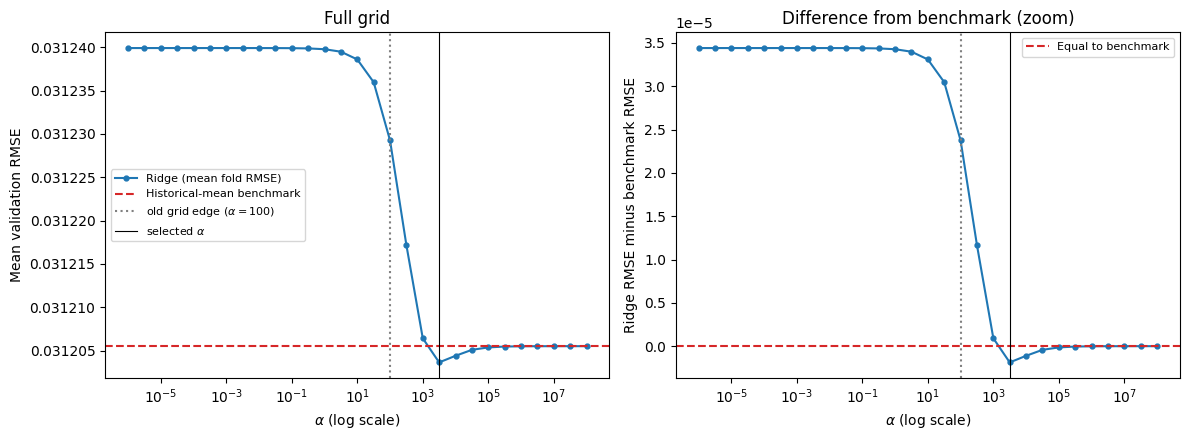

In [17]:
# ============================================================
# Extended alpha grid: validation error vs alpha (table + plot)
# ============================================================
# Requires (already in your notebook): development, features,
# validation_periods, and the imports of Ridge / StandardScaler.
# 1e-6 ... 1e8 in half-decade steps (30 values). The original grid stopped at 100.
alphas_ext = np.logspace(-6, 8, 29)

fold_rows = []
for alpha in alphas_ext:
    for k, (val_start, val_end) in enumerate(validation_periods, start=1):
        train = development[development.index < val_start]
        val = development[(development.index >= val_start) &
                          (development.index < val_end)]

        # scaler fitted on this fold's training data only
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(train[features])
        X_va = scaler.transform(val[features])

        model = Ridge(alpha=alpha).fit(X_tr, train["target"])
        err = val["target"].values - model.predict(X_va)

        # historical-mean benchmark for the same fold (training mean only)
        err_mean = val["target"].values - train["target"].mean()

        fold_rows.append({
            "alpha": alpha, "fold": k, "n_val": len(val),
            "MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "SSE": np.sum(err ** 2),
            "RMSE_mean_bench": np.sqrt(np.mean(err_mean ** 2)),
            "SSE_mean_bench": np.sum(err_mean ** 2),
        })

fold_df = pd.DataFrame(fold_rows)

# ---- aggregate across folds: (a) mean of fold RMSEs, (b) pooled RMSE ------
alpha_table = fold_df.groupby("alpha").agg(
    mean_MAE=("MAE", "mean"),
    mean_RMSE=("RMSE", "mean"),
    sd_RMSE=("RMSE", "std"),
).reset_index()

pooled = fold_df.groupby("alpha")[["SSE", "n_val"]].sum()
alpha_table["pooled_RMSE"] = (np.sqrt(pooled["SSE"] / pooled["n_val"])).values

bench_mean_RMSE = fold_df[fold_df["alpha"] == alphas_ext[0]]["RMSE_mean_bench"].mean()
alpha_table["RMSE_vs_mean_bench"] = alpha_table["mean_RMSE"] - bench_mean_RMSE

best_alpha_ext = alpha_table.loc[alpha_table["mean_RMSE"].idxmin(), "alpha"]
best_alpha_pooled = alpha_table.loc[alpha_table["pooled_RMSE"].idxmin(), "alpha"]

print("Validation error vs alpha (extended grid)\n")
print(alpha_table.to_string(index=False, formatters={
    "alpha": lambda v: f"{v:.3g}",
    **{c: (lambda v: f"{v:.8f}") for c in alpha_table.columns if c != "alpha"}}))
print(f"\nHistorical-mean benchmark, mean fold RMSE: {bench_mean_RMSE:.8f}")
print(f"Best alpha by mean fold RMSE: {best_alpha_ext:.6g}")
print(f"Best alpha by pooled RMSE:    {best_alpha_pooled:.6g}")
print(f"Best alpha is interior to the grid: "
      f"{alphas_ext[0] < best_alpha_ext < alphas_ext[-1]}")

# ---- plot ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# left: full range
ax = axes[0]
ax.semilogx(alpha_table["alpha"], alpha_table["mean_RMSE"], marker="o", ms=3.5,
            label="Ridge (mean fold RMSE)")
ax.axhline(bench_mean_RMSE, ls="--", color="tab:red", label="Historical-mean benchmark")
ax.axvline(100, ls=":", color="grey", label=r"old grid edge ($\alpha=100$)")
ax.axvline(best_alpha_ext, color="black", lw=0.8, label=r"selected $\alpha$")
ax.set_xlabel(r"$\alpha$ (log scale)")
ax.set_ylabel("Mean validation RMSE")
ax.set_title("Full grid")
ax.legend(fontsize=8)

# right: Ridge minus benchmark, zoomed so tiny differences are visible
ax = axes[1]
ax.semilogx(alpha_table["alpha"], alpha_table["RMSE_vs_mean_bench"], marker="o", ms=3.5)
ax.axhline(0, color="tab:red", ls="--", label="Equal to benchmark")
ax.axvline(100, ls=":", color="grey")
ax.axvline(best_alpha_ext, color="black", lw=0.8)
ax.set_xlabel(r"$\alpha$ (log scale)")
ax.set_ylabel("Ridge RMSE minus benchmark RMSE")
ax.set_title("Difference from benchmark (zoom)")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

In [18]:


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))

ALPHA_WEAK = 1e-6            # essentially unregularised: the "can overfit" case
ALPHA_SEL = best_alpha_ext   # selected by validation

rows = []
for k, (vs, ve) in enumerate(validation_periods, start=1):
    train = development[development.index < vs]
    val = development[(development.index >= vs) & (development.index < ve)]

    sc = StandardScaler()
    X_tr, X_va = sc.fit_transform(train[features]), sc.transform(val[features])
    y_tr, y_va = train["target"].values, val["target"].values
    mu = y_tr.mean()

    row = {"fold": k, "n_train": len(train), "n_val": len(val),
           "vol_train": y_tr.std(), "vol_val": y_va.std(),
           "mean_in": rmse(y_tr - mu), "mean_out": rmse(y_va - mu)}

    for tag, a in [("weak", ALPHA_WEAK), ("sel", ALPHA_SEL)]:
        m = Ridge(alpha=a).fit(X_tr, y_tr)
        row[f"{tag}_in"] = rmse(y_tr - m.predict(X_tr))
        row[f"{tag}_out"] = rmse(y_va - m.predict(X_va))
    rows.append(row)

ov = pd.DataFrame(rows).set_index("fold")

# Volatility-robust diagnostics: each model is compared with the benchmark
# on the SAME data, so a change in volatility between periods cancels out.
for tag in ("weak", "sel"):
    ov[f"{tag}_in_ratio"] = ov[f"{tag}_in"] / ov["mean_in"]     # <1: beats benchmark in-sample
    ov[f"{tag}_out_ratio"] = ov[f"{tag}_out"] / ov["mean_out"]  # <1: beats benchmark out-of-sample
    ov[f"{tag}_gap"] = ov[f"{tag}_out_ratio"] - ov[f"{tag}_in_ratio"]  # >0: advantage fades out-of-sample

print("Volatility of the target: training window vs validation window")
print(ov[["n_train", "n_val", "vol_train", "vol_val"]].assign(
    vol_ratio=ov["vol_val"] / ov["vol_train"]).to_string(float_format=lambda v: f"{v:.5f}"))

print("\nRMSE ratios relative to the historical-mean benchmark (same data, same fold)")
print(ov[["weak_in_ratio", "weak_out_ratio", "weak_gap",
          "sel_in_ratio", "sel_out_ratio", "sel_gap"]].to_string(
          float_format=lambda v: f"{v:.5f}"))

print("\nSummary over folds")
for tag, name in [("weak", f"alpha = {ALPHA_WEAK:g}"), ("sel", f"alpha = {ALPHA_SEL:.3g} (selected)")]:
    print(f"  {name}: mean in-sample ratio {ov[f'{tag}_in_ratio'].mean():.5f} | "
          f"mean validation ratio {ov[f'{tag}_out_ratio'].mean():.5f} | "
          f"folds beating benchmark out-of-sample: {(ov[f'{tag}_out_ratio'] < 1).sum()} of {len(ov)}")

Volatility of the target: training window vs validation window
      n_train  n_val  vol_train  vol_val  vol_ratio
fold                                               
1         497     62    0.03458  0.03385    0.97887
2         559     62    0.03467  0.03826    1.10363
3         621     63    0.03508  0.02458    0.70055
4         684     63    0.03425  0.02095    0.61174
5         747     61    0.03333  0.03153    0.94596
6         808     63    0.03328  0.03358    1.00918
7         871     64    0.03331  0.04044    1.21417
8         935     64    0.03386  0.02296    0.67811

RMSE ratios relative to the historical-mean benchmark (same data, same fold)
      weak_in_ratio  weak_out_ratio  weak_gap  sel_in_ratio  sel_out_ratio  sel_gap
fold                                                                               
1           0.99799         0.99578  -0.00221       0.99950        0.99910 -0.00040
2           0.99714         0.99378  -0.00336       0.99920        0.99863 -0.00058
3  

In [19]:
# ============================================================
# Expanding-window validation design: explicit fold documentation
# ============================================================
# Requires: development, validation_periods (list of (start, end) strings,
# validation window = [start, end) ).
rows = []
for k, (vs, ve) in enumerate(validation_periods, start=1):
    train = development[development.index < vs]
    val = development[(development.index >= vs) & (development.index < ve)]

    # --- integrity checks: the design is only valid if these all hold ---
    assert len(train) > 0 and len(val) > 0, f"Fold {k}: empty split"
    assert train.index.max() < val.index.min(), f"Fold {k}: training overlaps validation"
    assert train.index.is_monotonic_increasing, f"Fold {k}: training not chronological"

    rows.append({
        "Fold": k,
        "Train start": train.index.min().date(),
        "Train end": train.index.max().date(),
        "Train n": len(train),
        "Val start": val.index.min().date(),
        "Val end": val.index.max().date(),
        "Val n": len(val),
    })

fold_table = pd.DataFrame(rows)

# Training window of fold k+1 must contain the whole training window and
# validation window of fold k (that is what "expanding" means).
for k in range(len(fold_table) - 1):
    gap_days = fold_table.loc[k + 1, "Train n"] - (fold_table.loc[k, "Train n"] + fold_table.loc[k, "Val n"])
    assert gap_days == 0, f"Fold {k+1}->{k+2}: training window does not absorb previous validation window"

# Validation windows must not overlap each other, and together they cover
# the tail of the development period.
assert fold_table["Val n"].sum() == len(development[development.index >= validation_periods[0][0]])

print("Expanding-window validation design\n")
print(fold_table.to_string(index=False))

print(f"\nDevelopment period:   {development.index.min().date()} to {development.index.max().date()}  "
      f"(n = {len(development)})")
print(f"Total validation obs: {fold_table['Val n'].sum()}  across {len(fold_table)} folds "
      f"(mean {fold_table['Val n'].mean():.1f}, min {fold_table['Val n'].min()}, max {fold_table['Val n'].max()})")
print(f"Training size range:  {fold_table['Train n'].min()} to {fold_table['Train n'].max()}")
print("Integrity checks passed: no train/validation overlap, chronological order, "
      "expanding windows, non-overlapping validation windows.")

fold_table.to_csv("table_expanding_window_folds.csv", index=False)

Expanding-window validation design

 Fold Train start  Train end  Train n  Val start    Val end  Val n
    1  2021-01-12 2022-12-30      497 2023-01-03 2023-03-31     62
    2  2021-01-12 2023-03-31      559 2023-04-03 2023-06-30     62
    3  2021-01-12 2023-06-30      621 2023-07-03 2023-09-29     63
    4  2021-01-12 2023-09-29      684 2023-10-02 2023-12-29     63
    5  2021-01-12 2023-12-29      747 2024-01-02 2024-03-28     61
    6  2021-01-12 2024-03-28      808 2024-04-01 2024-06-28     63
    7  2021-01-12 2024-06-28      871 2024-07-01 2024-09-30     64
    8  2021-01-12 2024-09-30      935 2024-10-01 2024-12-31     64

Development period:   2021-01-12 to 2024-12-31  (n = 999)
Total validation obs: 502  across 8 folds (mean 62.8, min 61, max 64)
Training size range:  497 to 935
Integrity checks passed: no train/validation overlap, chronological order, expanding windows, non-overlapping validation windows.


In [20]:

def mae(e):  return float(np.mean(np.abs(e)))
def rmse(e): return float(np.sqrt(np.mean(np.square(e))))

# ---------------- 1. Validation folds: three models, same days ---------------
fold_rows = []
for k, (vs, ve) in enumerate(validation_periods, start=1):
    train = development[development.index < vs]
    val = development[(development.index >= vs) & (development.index < ve)]
    y_va = val["target"].values

    sc = StandardScaler()
    X_tr, X_va = sc.fit_transform(train[features]), sc.transform(val[features])
    ridge = Ridge(alpha=best_alpha_ext).fit(X_tr, train["target"])

    forecasts = {
        "Ridge": ridge.predict(X_va),
        "Historical mean": np.full(len(val), train["target"].mean()),  # training mean only
        "Zero": np.zeros(len(val)),
    }
    for name, f in forecasts.items():
        e = y_va - f
        fold_rows.append({"fold": k, "model": name, "n_val": len(val),
                          "MAE": mae(e), "RMSE": rmse(e),
                          "SSE": float(np.sum(e**2)), "mean_forecast": float(np.mean(f))})

folds3 = pd.DataFrame(fold_rows)

val_summary = folds3.groupby("model").agg(mean_MAE=("MAE", "mean"),
                                          mean_RMSE=("RMSE", "mean"))
pool = folds3.groupby("model")[["SSE", "n_val"]].sum()
val_summary["pooled_RMSE"] = np.sqrt(pool["SSE"] / pool["n_val"])
val_summary = val_summary.loc[["Ridge", "Historical mean", "Zero"]]

print("Validation (8 expanding-window folds): Ridge vs both benchmarks")
print(val_summary.to_string(float_format=lambda v: f"{v:.8f}"))

wide = folds3.pivot(index="fold", columns="model", values="RMSE")[["Ridge", "Historical mean", "Zero"]]
print("\nPer-fold RMSE")
print(wide.to_string(float_format=lambda v: f"{v:.6f}"))
print(f"\nFolds where Ridge beats Zero:            {(wide['Ridge'] < wide['Zero']).sum()} of {len(wide)}")
print(f"Folds where Historical mean beats Zero:  {(wide['Historical mean'] < wide['Zero']).sum()} of {len(wide)}")

# ---------------- 2. Final test year ------------------------------------------
sc = StandardScaler()
X_dev = sc.fit_transform(development[features])
X_te = sc.transform(test[features])
y_dev, y_te = development["target"].values, test["target"].values

final_ridge = Ridge(alpha=best_alpha_ext).fit(X_dev, development["target"])
mu_dev = y_dev.mean()

test_forecasts = {
    "Ridge": final_ridge.predict(X_te),
    "Historical mean": np.full(len(y_te), mu_dev),
    "Zero": np.zeros(len(y_te)),
}

test_rows = []
for name, f in test_forecasts.items():
    e = y_te - f
    test_rows.append({"Model": name, "MAE": mae(e), "RMSE": rmse(e)})
test_table = pd.DataFrame(test_rows).set_index("Model")
test_table["RMSE vs Zero (%)"] = 100 * (test_table["RMSE"] / test_table.loc["Zero", "RMSE"] - 1)

print("\nFinal test, 2025")
print(test_table.to_string(float_format=lambda v: f"{v:.8f}"))
print(f"\nHistorical-mean forecast (development-period mean daily return): {mu_dev:.6f}")
print(f"Mean realized return in 2025:                                    {y_te.mean():.6f}")

# ---------------- 3. Paired loss differentials, ready for the bootstrap -------
# d_t = loss(benchmark) - loss(Ridge): positive means Ridge better that day.
test_predictions_ridge = test_forecasts["Ridge"]
zero_predictions = test_forecasts["Zero"]
d_sq_vs_zero = (y_te - zero_predictions) ** 2 - (y_te - test_predictions_ridge) ** 2
d_abs_vs_zero = np.abs(y_te - zero_predictions) - np.abs(y_te - test_predictions_ridge)
print(f"\nMean paired loss differential, Ridge vs Zero (positive = Ridge better): "
      f"squared {d_sq_vs_zero.mean():.3e}, absolute {d_abs_vs_zero.mean():.3e}")

Validation (8 expanding-window folds): Ridge vs both benchmarks
                  mean_MAE  mean_RMSE  pooled_RMSE
model                                             
Ridge           0.02298858 0.03120364   0.03195132
Historical mean 0.02299503 0.03120552   0.03194879
Zero            0.02316201 0.03140955   0.03215473

Per-fold RMSE
model    Ridge  Historical mean     Zero
fold                                    
1     0.035471         0.035503 0.035727
2     0.038599         0.038652 0.038969
3     0.024598         0.024609 0.024603
4     0.020975         0.020974 0.020997
5     0.032646         0.032682 0.033346
6     0.033669         0.033696 0.034055
7     0.040724         0.040571 0.040443
8     0.022948         0.022957 0.023138

Folds where Ridge beats Zero:            7 of 8
Folds where Historical mean beats Zero:  6 of 8

Final test, 2025
                       MAE       RMSE  RMSE vs Zero (%)
Model                                                  
Ridge           0.02159476 0.

Per-fold Ridge coefficients, alpha = 3.16e+03 (standardized features)
          lag_1      lag_2      lag_3     lag_4     lag_5
fold                                                     
1     1.208e-05 -9.610e-05 -9.425e-05 1.872e-04 1.834e-04
2    -1.296e-04 -1.095e-04 -1.589e-05 2.385e-04 2.640e-04
3    -1.288e-04 -2.076e-04 -3.188e-05 3.000e-04 2.800e-04
4    -1.284e-04 -2.303e-04 -3.825e-05 3.472e-04 2.368e-04
5    -1.126e-04 -2.342e-04 -2.840e-05 3.484e-04 2.548e-04
6    -2.036e-04 -1.982e-04 -5.015e-05 3.761e-04 2.685e-04
7    -2.319e-04 -2.153e-04 -5.044e-05 3.709e-04 2.859e-04
8    -2.154e-05 -2.621e-04  4.329e-05 2.036e-04 3.040e-04

Stability summary, selected alpha
            mean        sd    mean/sd        min        max  n_negative  sign_consistent
lag_1 -1.181e-04 8.187e-05 -1.442e+00 -2.319e-04  1.208e-05           7            False
lag_2 -1.942e-04 5.971e-05 -3.252e+00 -2.621e-04 -9.610e-05           8             True
lag_3 -3.325e-05 3.875e-05 -8.579e-01 -9.425e-05

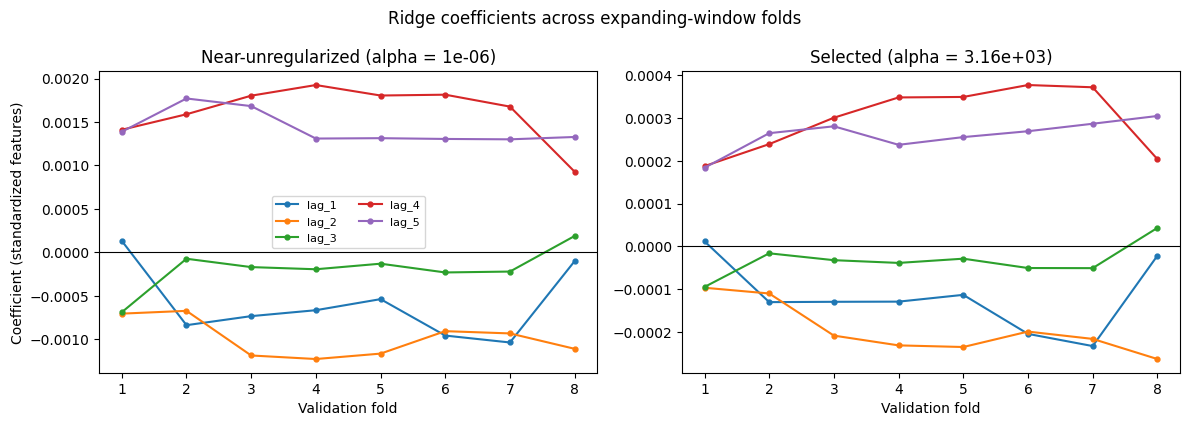

In [21]:
ALPHA_SEL = best_alpha_ext
ALPHA_WEAK = 1e-6          # near-OLS reference: what the data "wants" without shrinkage

coef_sel, coef_weak, shrink, pred_sd = [], [], [], []
for k, (vs, ve) in enumerate(validation_periods, start=1):
    train = development[development.index < vs]
    val = development[(development.index >= vs) & (development.index < ve)]

    sc = StandardScaler()                         # fitted on this fold's training data only
    X_tr, X_va = sc.fit_transform(train[features]), sc.transform(val[features])
    y_tr = train["target"]

    m_sel = Ridge(alpha=ALPHA_SEL).fit(X_tr, y_tr)
    m_weak = Ridge(alpha=ALPHA_WEAK).fit(X_tr, y_tr)

    coef_sel.append(m_sel.coef_)
    coef_weak.append(m_weak.coef_)
    shrink.append(np.linalg.norm(m_sel.coef_) / np.linalg.norm(m_weak.coef_))
    pred_sd.append(m_sel.predict(X_va).std() / val["target"].std())

C_sel = pd.DataFrame(coef_sel, columns=features, index=pd.RangeIndex(1, len(validation_periods) + 1, name="fold"))
C_weak = pd.DataFrame(coef_weak, columns=features, index=C_sel.index)

# ---------------- 1. Per-fold coefficients and stability summary --------------
def stability(C):
    return pd.DataFrame({
        "mean": C.mean(),
        "sd": C.std(),
        "mean/sd": C.mean() / C.std(),
        "min": C.min(),
        "max": C.max(),
        "n_negative": (C < 0).sum(),
        "sign_consistent": (C < 0).all() | (C > 0).all(),
    })

print(f"Per-fold Ridge coefficients, alpha = {ALPHA_SEL:.3g} (standardized features)")
print(C_sel.to_string(float_format=lambda v: f"{v:.3e}"))
print("\nStability summary, selected alpha")
print(stability(C_sel).to_string(float_format=lambda v: f"{v:.3e}"))

print(f"\nPer-fold coefficients, near-unregularized reference (alpha = {ALPHA_WEAK:g})")
print(C_weak.to_string(float_format=lambda v: f"{v:.3e}"))
print("\nStability summary, near-unregularized")
print(stability(C_weak).to_string(float_format=lambda v: f"{v:.3e}"))

# ---------------- 2. How close is the model to the baseline? -----------------
print(f"\nCoefficient norm at selected alpha, as a fraction of the near-OLS norm: "
      f"mean {np.mean(shrink):.4f} (min {np.min(shrink):.4f}, max {np.max(shrink):.4f})")
print(f"Std of Ridge validation forecasts as a fraction of std of realized returns: "
      f"mean {np.mean(pred_sd):.5f}")

# ---------------- 3. Final-fit coefficients on the full development period ----
sc = StandardScaler()
X_dev = sc.fit_transform(development[features])
final = Ridge(alpha=ALPHA_SEL).fit(X_dev, development["target"])
final_weak = Ridge(alpha=ALPHA_WEAK).fit(X_dev, development["target"])

final_table = pd.DataFrame({
    f"Ridge (alpha={ALPHA_SEL:.3g})": final.coef_,
    f"near-OLS (alpha={ALPHA_WEAK:g})": final_weak.coef_,
    "fold mean (selected)": C_sel.mean().values,
}, index=features)
print("\nFinal-fit coefficients (full 2021-2024 development period, standardized features)")
print(final_table.to_string(float_format=lambda v: f"{v:.3e}"))
print(f"Intercept (= development mean target): {final.intercept_:.6f}")

# ---------------- 4. Figure: coefficients by fold, selected vs near-OLS ------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True)
for ax, C, title in [(axes[0], C_weak, f"Near-unregularized (alpha = {ALPHA_WEAK:g})"),
                     (axes[1], C_sel, f"Selected (alpha = {ALPHA_SEL:.3g})")]:
    for f in features:
        ax.plot(C.index, C[f], marker="o", ms=3.5, label=f)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Validation fold")
    ax.set_title(title)
axes[0].set_ylabel("Coefficient (standardized features)")
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle("Ridge coefficients across expanding-window folds")
fig.tight_layout()
plt.show()

stability(C_sel).to_csv("table_coef_stability_selected.csv")
stability(C_weak).to_csv("table_coef_stability_weak.csv")

In [22]:
best_alpha_ext = 3162.0 
# ============================================================
# Block bootstrap on paired forecast-loss differentials
# ============================================================
# Requires (already in your notebook):
#   y_test                    : realized next-day returns, 2025 (pd.Series)
#   test_predictions          : Ridge forecasts for 2025
#   test_baseline_predictions : historical-mean forecasts for 2025
rng = np.random.default_rng(12345)          # fixed seed -> reproducible CIs

def loss_differential(y, f_ridge, f_bench, loss="squared"):
    """d_t = L(benchmark error) - L(Ridge error).
    d_t > 0  <=>  Ridge was better on day t."""
    e_r = np.asarray(y) - np.asarray(f_ridge)
    e_b = np.asarray(y) - np.asarray(f_bench)
    if loss == "squared":
        return e_b**2 - e_r**2
    if loss == "absolute":
        return np.abs(e_b) - np.abs(e_r)
    raise ValueError("loss must be 'squared' or 'absolute'")

def moving_block_bootstrap_mean(d, block_len, n_boot=10_000, rng=rng):
    """Resample overlapping blocks of consecutive d_t (keeps serial dependence,
    e.g. volatility clustering) and return the bootstrap means of d."""
    d = np.asarray(d, dtype=float)
    n = len(d)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, n - block_len + 1, size=(n_boot, n_blocks))
    idx = (starts[:, :, None] + np.arange(block_len)).reshape(n_boot, -1)[:, :n]
    return d[idx].mean(axis=1)

def bootstrap_loss_test(y, f_ridge, f_bench, loss="squared",
                        block_len=None, n_boot=10_000, level=0.95):
    d = loss_differential(y, f_ridge, f_bench, loss)
    n = len(d)
    if block_len is None:
        block_len = max(1, int(round(n ** (1 / 3))))   # common rule of thumb

    boot_means = moving_block_bootstrap_mean(d, block_len, n_boot)
    d_bar = d.mean()

    lo, hi = np.percentile(boot_means, [100 * (1 - level) / 2, 100 * (1 + level) / 2])

    # p-value: bootstrap distribution re-centred on 0 to impose H0: E[d_t] = 0
    centred = boot_means - d_bar
    p_two = np.mean(np.abs(centred) >= abs(d_bar))
    p_one = np.mean(centred >= d_bar)            # H1: Ridge better (d_bar > 0)

    return {"loss": loss, "block_len": block_len, "n": n,
            "mean_d": d_bar, "ci_low": lo, "ci_high": hi,
            "p_two_sided": p_two, "p_one_sided_ridge_better": p_one}

# ---- run it: Ridge vs each benchmark, both losses -------------------------
zero_predictions = np.zeros(len(y_test))
benchmarks = {"Historical mean": test_baseline_predictions,
              "Zero": zero_predictions}

rows = []
for name, f_b in benchmarks.items():
    for loss in ("squared", "absolute"):
        r = bootstrap_loss_test(y_test.values, test_predictions, f_b, loss=loss)
        r["benchmark"] = name
        rows.append(r)

boot_results = pd.DataFrame(rows)[["benchmark", "loss", "block_len", "n", "mean_d",
                                   "ci_low", "ci_high", "p_two_sided",
                                   "p_one_sided_ridge_better"]]
print("Positive mean_d = Ridge has lower loss than the benchmark.\n")
print(boot_results.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

# ---- sensitivity to block length (does the conclusion depend on it?) -------
print("\nSensitivity of the squared-loss CI to block length (vs historical mean):")
for L in (1, 3, 5, 10, 20):
    r = bootstrap_loss_test(y_test.values, test_predictions, test_baseline_predictions,
                            loss="squared", block_len=L)
    print(f"  block = {L:>2}: mean_d = {r['mean_d']: .3e}   "
          f"95% CI [{r['ci_low']: .3e}, {r['ci_high']: .3e}]   p = {r['p_two_sided']:.3f}")

Positive mean_d = Ridge has lower loss than the benchmark.

      benchmark     loss  block_len   n    mean_d     ci_low   ci_high  p_two_sided  p_one_sided_ridge_better
Historical mean  squared          6 249 7.736e-06 -5.601e-06 2.351e-05    2.830e-01                 1.375e-01
Historical mean absolute          6 249 6.588e-06 -1.349e-04 1.539e-04    9.297e-01                 4.730e-01
           Zero  squared          6 249 9.182e-06 -1.522e-05 3.353e-05    4.577e-01                 2.138e-01
           Zero absolute          6 249 1.237e-04 -1.907e-04 4.685e-04    4.724e-01                 2.725e-01

Sensitivity of the squared-loss CI to block length (vs historical mean):
  block =  1: mean_d =  7.736e-06   95% CI [-6.662e-06,  2.377e-05]   p = 0.323
  block =  3: mean_d =  7.736e-06   95% CI [-6.576e-06,  2.402e-05]   p = 0.316
  block =  5: mean_d =  7.736e-06   95% CI [-5.878e-06,  2.376e-05]   p = 0.305
  block = 10: mean_d =  7.736e-06   95% CI [-4.364e-06,  2.343e-05]   p = 0.